<a href="https://colab.research.google.com/github/naufalrahmanu/Submission-Asah-Deep-Learning/blob/main/Submission_Akhir_Asah_Revisi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Klasifikasi Gambar: [Input Nama Dataset]
- **Nama:** Muhammad Naufal Rahmanu Anindito
- **Email:** muhammadnaufalrahmanuanindito@mail.ugm.ac.id
- **ID Dicoding:** ae008b6y1212

## Import Semua Packages/Library yang Digunakan

In [8]:
!pip install kagglehub tensorflow -q

## Data Preparation

### Data Loading

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hasnainjaved/melanoma-skin-cancer-dataset-of-10000-images")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'melanoma-skin-cancer-dataset-of-10000-images' dataset.
Path to dataset files: /kaggle/input/melanoma-skin-cancer-dataset-of-10000-images


### Data Preprocessing

#### Split Dataset

In [9]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Menggunakan path dinamis yang dihasilkan oleh kagglehub
try:
    base_dir = os.path.join(path, 'melanoma_cancer_dataset')
except NameError:
    import kagglehub
    download_path = kagglehub.dataset_download("hasnainjaved/melanoma-skin-cancer-dataset-of-10000-images")
    base_dir = os.path.join(download_path, 'melanoma_cancer_dataset')

train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')

# Parameter Gambar
IMAGE_SIZE = (150, 150)  # Ukuran gambar yang akan di-resize
BATCH_SIZE = 32

# Generator untuk split Training dan Validation (80% Train, 20% Validation)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2 # Menentukan 20% data training untuk validasi
)

# Generator untuk Test Set
test_datagen = ImageDataGenerator(rescale=1./255)

# Memisahkan subset Train
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    seed=42
)

# Memisahkan subset Validation
val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    seed=42
)

# Memisahkan dataset Test
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# Menampilkan informasi kelas
print("Kelas yang ditemukan:", train_generator.class_indices)

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


Found 7684 images belonging to 2 classes.
Found 1921 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Kelas yang ditemukan: {'benign': 0, 'malignant': 1}


## Modelling

In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Membangun Model CNN Sequential
model = Sequential([
    # Blok Konvolusi Pertama
    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    MaxPooling2D(2, 2),

    # Blok Konvolusi Kedua
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Blok Konvolusi Ketiga
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Blok Konvolusi Keempat
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Meratakan output untuk lapisan fully connected
    Flatten(),

    # Dense Layer / Fully Connected Layer
    Dense(512, activation='relu'),
    Dropout(0.5),  # Regularisasi untuk mengurangi overfitting

    # Output Layer (Binary classification: benign atau malignant)
    Dense(1, activation='sigmoid')
])

# Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Menampilkan ringkasan struktur model
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Melatih model selama 20 epochs
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator,
    verbose=1
)

Epoch 1/20
241/241 ━━━━━━━━━━━━━━━━━━━━ 194s 800ms/step - accuracy: 0.7500 - loss: 0.4836 - val_accuracy: 0.8444 - val_loss: 0.3744
Epoch 2/20
241/241 ━━━━━━━━━━━━━━━━━━━━ 165s 685ms/step - accuracy: 0.8363 - loss: 0.3749 - val_accuracy: 0.8766 - val_loss: 0.3234
Epoch 3/20
241/241 ━━━━━━━━━━━━━━━━━━━━ 165s 685ms/step - accuracy: 0.8611 - loss: 0.3318 - val_accuracy: 0.8813 - val_loss: 0.3042
Epoch 4/20
241/241 ━━━━━━━━━━━━━━━━━━━━ 165s 685ms/step - accuracy: 0.8656 - loss: 0.3185 - val_accuracy: 0.8673 - val_loss: 0.3221
Epoch 5/20
241/241 ━━━━━━━━━━━━━━━━━━━━ 165s 684ms/step - accuracy: 0.8704 - loss: 0.3075 - val_accuracy: 0.8912 - val_loss: 0.2774
Epoch 6/20
241/241 ━━━━━━━━━━━━━━━━━━━━ 164s 682ms/step - accuracy: 0.8748 - loss: 0.3075 - val_accuracy: 0.8761 - val_loss: 0.2983
Epoch 7/20
241/241 ━━━━━━━━━━━━━━━━━━━━ 165s 684ms/step - accuracy: 0.8775 - loss: 0.2906 - val_accuracy: 0.8667 - val_loss: 0.3018
Epoch 8/20
241/241 ━━━━━━━━━━━━━━━━━━━━ 164s 681ms/step - accuracy: 0.8805 -

## Evaluasi dan Visualisasi

32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 283ms/step - accuracy: 0.9040 - loss: 0.2325

--- Hasil Evaluasi Test Set ---
Test Loss: 0.2325
Test Accuracy: 90.40%


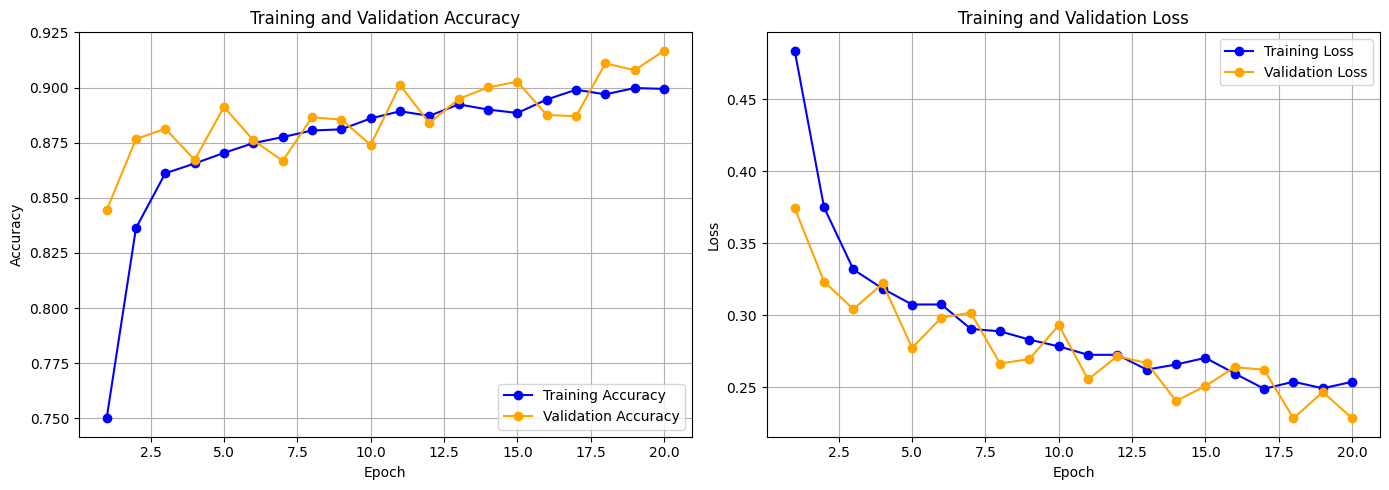

In [12]:
import matplotlib.pyplot as plt

# 1. Evaluasi model pada test set secara penuh
test_loss, test_accuracy = model.evaluate(test_generator, verbose=1)
print("\n--- Hasil Evaluasi Test Set ---")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# 2. Plot Akurasi dan Loss Model
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Plot Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='blue', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

## Konversi Model

In [13]:
import tensorflow as tf

# 1. Menginisialisasi Converter dari model Keras yang telah dilatih
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# 2. Melakukan konversi model
tflite_model = converter.convert()

# 3. Menyimpan model TFLite ke dalam file lokal
tflite_model_path = 'melanoma_classification_model.tflite'
with open(tflite_model_path, 'wb') as f:
    f.write(tflite_model)

print(f"Model berhasil dikonversi dan disimpan di: {tflite_model_path}")

Saved artifact at '/tmp/tmp08ire_23'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  137385999929936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999929168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999930704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999931472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999931280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999931856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999931088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999932048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999930128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999932432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13738599993166

In [14]:
# Menyimpan model ke format TensorFlow SavedModel menggunakan Keras 3
saved_model_path = 'saved_model/melanoma_model'
model.export(saved_model_path)
print(f"Model berhasil disimpan dalam format SavedModel di: {saved_model_path}")

Saved artifact at 'saved_model/melanoma_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  137385999929936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999929168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999930704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999931472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999931280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999931856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999931088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999932048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999930128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137385999932432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1373

In [15]:
# 1. Install setuptools, tensorflowjs, dan tensorflow-estimator
!pip install setuptools tensorflowjs tensorflow-estimator -q

import os
import tensorflow as tf

# 2. Tentukan direktori output TFJS
tfjs_model_dir = 'melanoma_tfjs_model'
os.makedirs(tfjs_model_dir, exist_ok=True)

# 3. Path dari SavedModel yang sudah dibuat sebelumnya di sel g2b6uMAOylBh
saved_model_path = 'saved_model/melanoma_model'

# 4. Buat skrip Python penolong untuk melakukan patch numpy dan memanggil konversi dari SavedModel
with open('convert_patch.py', 'w') as f:
    f.write('''
import sys
import os
import types
import numpy as np

# Patch NumPy
np.object = object

# Mocking modul internal tensorflow yang hilang di versi baru
mock_tracking = types.ModuleType("tensorflow.python.training.tracking")
mock_tracking.data_structures = types.ModuleType("tensorflow.python.training.tracking.data_structures")
sys.modules["tensorflow.python.training.tracking"] = mock_tracking
sys.modules["tensorflow.python.training.tracking.data_structures"] = mock_tracking.data_structures

# Import TensorFlow
import tensorflow as tf

# Buat Dummy Estimator
class DummyEstimator(object):
    class Exporter(object):
        pass

# Bajak tensorflow.compat.v1 sebelum hub di-import
try:
    import tensorflow_estimator
    tf.compat.v1.estimator = tensorflow_estimator.estimator
except Exception:
    tf.compat.v1.estimator = DummyEstimator()

# Daftarkan secara paksa ke sys.modules jika wrapper melarang manipulasi langsung
class CompatV1Wrapper(object):
    def __init__(self, wrapped):
        self._wrapped = wrapped
        self.estimator = DummyEstimator()
    def __getattr__(self, name):
        return getattr(self._wrapped, name)

sys.modules["tensorflow.compat.v1"] = CompatV1Wrapper(tf.compat.v1)

from tensorflowjs.converters.converter import pip_main

if __name__ == "__main__":
    # Gunakan input_format=tf_saved_model karena kita mengonversi dari folder SavedModel
    sys.argv = [
        "tensorflowjs_converter",
        "--input_format=tf_saved_model",
        "saved_model/melanoma_model",
        "melanoma_tfjs_model"
    ]
    pip_main()
''')

# 5. Jalankan konversi menggunakan skrip yang telah dipatch secara mendalam
print("Memulai konversi SavedModel ke format TFJS dengan Deep Patching...")
!PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION=python python convert_patch.py

# 6. Bersihkan berkas penolong
if os.path.exists('convert_patch.py'):
    os.remove('convert_patch.py')

print(f"Proses konversi selesai. Silakan periksa direktori: {tfjs_model_dir}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scikit-image 0.25.2 requires packaging>=21, but you have packaging 20.9 which is incompatible.
jupyter-server 2.20.0 requires packaging>=22.0, but you have packaging 20.9 which is incompatible.
Memulai konversi SavedModel ke format TFJS dengan Deep Patching...
I0000 00:00:1793420899.587923   32212 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo s

## Inference (Optional)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


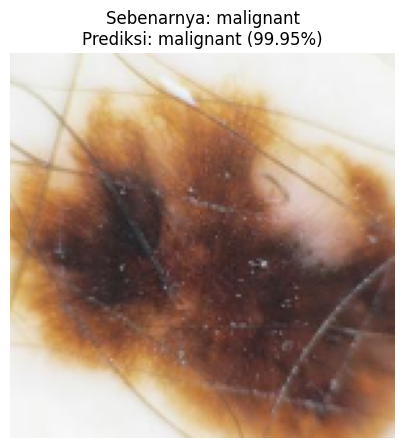

In [16]:
# Memastikan tensorflow terpasang di runtime
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
import random
import os
import tensorflow as tf

# 1. Gunakan path asli dari unduhan kagglehub
try:
    # Mengambil variabel 'path' dari session
    base_dir = os.path.join(path, 'melanoma_cancer_dataset')
except NameError:
    # Fallback jika session ter-reset
    import kagglehub
    download_path = kagglehub.dataset_download("hasnainjaved/melanoma-skin-cancer-dataset-of-10000-images")
    base_dir = os.path.join(download_path, 'melanoma_cancer_dataset')

test_dir = os.path.join(base_dir, 'test')

# Mendeteksi subdirektori (kelas) secara dinamis dari direktori test
classes = [d for d in os.listdir(test_dir) if os.path.isdir(os.path.join(test_dir, d))]
random_class = random.choice(classes)
class_path = os.path.join(test_dir, random_class)
random_image_name = random.choice(os.listdir(class_path))
image_path = os.path.join(class_path, random_image_name)

# 2. Muat dan preprocess gambar
img = image.load_img(image_path, target_size=(150, 150))
img_array = image.img_to_array(img)
img_array = img_array / 255.0  # Normalisasi sesuai dengan data generator
img_array = np.expand_dims(img_array, axis=0)  # Menambah dimensi batch

# 3. Lakukan prediksi menggunakan model (Load model dari disk jika variabel tidak ada)
try:
    model
except NameError:
    saved_model_path = 'saved_model/melanoma_model'
    print(f"Variabel 'model' tidak ditemukan di memori. Memuat model dari {saved_model_path}...")
    model = tf.keras.models.load_model(saved_model_path)

prediction = model.predict(img_array)
probability = prediction[0][0]

# Tentukan label berdasarkan nilai probabilitas sigmoid
if probability > 0.5:
    predicted_label = 'malignant'
    confidence = probability
else:
    predicted_label = 'benign'
    confidence = 1 - probability

# 4. Tampilkan hasil prediksi beserta gambar
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"Sebenarnya: {random_class}\nPrediksi: {predicted_label} ({confidence*100:.2f}%)")
plt.axis('off')
plt.show()

In [20]:
!pip freeze > requirements.txt